# 🧪 LAB: Implement an autoencoder with `PyTorch`

In this lab, you will implement and explore autoencoders using the MNIST dataset. The goal is to understand how autoencoders learn compressed representations of data, and how these representations compare with classical methods like PCA.

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = ""

## 1. Theoretical Background Reflection (10 points)

Read *Michelucci (2022)*: [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898) — focus on the following sections:  
- 1. Introduction
- 2.1, 2.2, and 2.3
- Skim Section 3 on applications  

Then answer briefly:

1. What is the main idea behind an autoencoder?  
2. What is the role of the bottleneck layer?  
3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.  
4. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?


1. The main idea behind an autoencoder is to squeeze the input down into a much smaller representation (the latent code) with an encoder, and then rebuild the original input from that code with a decoder. It is trained to make the reconstruction match the input, so it does not need labels, and the compressed code ends up being a useful summary of the data.

2. The bottleneck is the narrowest layer of the network, with far fewer units than the input. Since everything has to pass through it, the network cannot just copy the input to the output, so it has to keep only the most important information needed to reconstruct the input. That compressed code is what we use as the reduced representation.

3. One application is dimensionality reduction. Too many dimensions is a problem (the curse of dimensionality), so compressing the features helps, and autoencoders can handle large datasets since they train in mini-batches. Another is anomaly detection. The autoencoder is trained on data without outliers, so it reconstructs normal observations well and reconstructs outliers badly, and that large reconstruction error is what flags them. The downside is that it can overfit and give unstable results. A third is denoising, where the autoencoder is trained to rebuild the clean input from a noisy version, so it acts like a filter for noise.

4. An autoencoder and PCA give equivalent dimensionality reductions only if the encoder is linear, the decoder is linear, MSE is the loss function, and the inputs are normalized using equation (22) in the paper. Otherwise, an autoencoder can capture nonlinear structure because its layers can use nonlinear activations, while PCA is limited to linear combinations of the features. We would also expect PCA components to be orthogonal and ordered by explained variance, while the autoencoder's latent dimensions have no such constraints.

## 2. Prepare the Data (10 points)

Given the below dataset:

- Normalize **each** image (i.e., separately) so its values are between 0 and 1. Remember our first-week discussions of fixed and fitted transformations.
- Visualize a few random digits to confirm everything worked as expected.
- Split the dataset into fitting, tuning and reporting sets (70%, 15%, 15%).
- Wrap each data splitting as `DataLoader` object with a batch size of 128. Call them `fitting_loader`, `tuning_loader` and `reporting_loader`, respectively.

In [4]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1, as_frame=False, n_retries=5, delay=2)
X, y = mnist.data, mnist.target.astype(int)

In [5]:
print(X)
print(X.shape)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
(70000, 784)


min: 0.0 max: 1.0


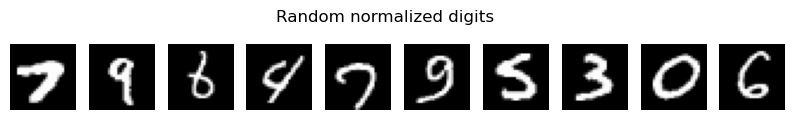

49000 10500 10500


In [6]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np
import torch

# normalize each image on its own to [0, 1]
X = X.astype('float32')
mins = X.min(axis=1, keepdims=True)
maxs = X.max(axis=1, keepdims=True)
X = (X - mins) / (maxs - mins + 1e-8)
print("min:", X.min(), "max:", X.max())

def show_images(imgs, n=10, title=None):
    plt.figure(figsize=(n, 1.4))
    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(imgs[i].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
        plt.axis('off')
    if title:
        plt.suptitle(title)
    plt.show()

# random digits to confirm it worked
rng = np.random.default_rng(42)
idx = rng.choice(len(X), 10, replace=False)
show_images(X[idx], title="Random normalized digits")

# 70 / 15 / 15 split: fitting / tuning / reporting
X_fit, X_rest, y_fit, y_rest = train_test_split(X, y, train_size=0.70, random_state=42)
X_tune, X_report, y_tune, y_report = train_test_split(X_rest, y_rest, train_size=0.50, random_state=42)

def make_dataset(Xa, ya):
    return TensorDataset(torch.from_numpy(Xa), torch.from_numpy(ya))

fitting_loader = DataLoader(make_dataset(X_fit, y_fit), batch_size=128, shuffle=True)
tuning_loader = DataLoader(make_dataset(X_tune, y_tune), batch_size=128, shuffle=False)
reporting_loader = DataLoader(make_dataset(X_report, y_report), batch_size=128, shuffle=False)

print(len(X_fit), len(X_tune), len(X_report))

## 3. Autoencoder

In this section, you will build and train an **autoencoder** to reconstruct the provided data.

Your model will include three layers in both the encoder and decoder:

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Implementation (30 points)

Follow the skeleton provided below and fill in the missing parts (`#TODO`). 

Follow these restrictions:

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. Determine the appropriate order for these components based on what we discussed in class. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [7]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        # ENCODING PART: 784 -> 128 -> 64 -> 2
        encoder_list = [
            # TODO: Add steps to go from 784 to 128 
            nn.Linear(784, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p=0.2),
            # TODO: Add steps to go from 128 to 64 
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(p=0.2),
            # TODO: Add steps to go from 64 to 2. 
            nn.Linear(64, 2),
        ]
        # TODO: Replace the None value below with the module that stores the layers in 'encoder_list' for manual iteration in the forward pass
        # Hint: we have covered this module in class
        self.encoder_list = nn.ModuleList(encoder_list)
        
        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            # TODO: Add steps to go from 2 to 64
            nn.Linear(2, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(p=0.2),
            # TODO: Add steps to go from 64 to 128  
            nn.Linear(64, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p=0.2),
            # TODO: Add steps to go from 128 to 784. 
            nn.Linear(128, 784), nn.Sigmoid(),
        ]
        # TODO: Replace the None value below with the module that stores the layers in 'decoder_list' for manual iteration in the forward pass
        # Hint: we have covered this module in class
        self.decoder_list = nn.ModuleList(decoder_list)

    def encode(self, X):
        # helper that runs only the encoder (used in Section 4 for the latent features)
        for layer in self.encoder_list:
            X = layer(X)
        return X
        
    def forward(self, X):
        # TODO: Replace the None value below for that after applying X -> encoder -> decoder
        # Hint: You will probably need to iterate through the encoder_list and decoder_list
        output = self.encode(X)
        for layer in self.decoder_list:
            output = layer(output)
        return output

In [8]:
test = Autoencoder()
xb, _ = next(iter(fitting_loader))
print(test(xb).shape, test.encode(xb).shape)

torch.Size([128, 784]) torch.Size([128, 2])


### 3.2 Training (15 points)

Follow the skeleton provided below and fill in the missing parts to train your model (`#TODO`). As you can see, training includes EarlyStopping, which I give you already for your convenience :-). After you have filled these missing parts, uncomment the provided piece of code with the function for training (`train_autoencoder`) your model and execute it.

But, **BEFORE** that, discuss with your mates and provide elaborated answers to the following:

- Why do you think the output layer of the autoencoder above uses a Sigmoid activation?
- Based on this, which cost function is most appropriate for this task? Justify your choice.

1. The sigmoid activation function keeps the output values between 0 and 1. This matches the range of our normalized pixel values. This ensures the reconstructed images have valid pixel intensities.

2. Mean Squared Error (MSE) is appropriate because we are reconstructing continuous pixel values between 0 and 1. MSE measures the average squared differences between the original and reconstructed pixels. Minimizing this helps the autoencoder produce more accurate reconstructions.

Once you have discussed and agreed on the reasoning above, proceed to complete the skeleton (`#TODO`) and train the model.


In [9]:
# TODO: Replace None to instantiate the autoencoder
model = Autoencoder()

# TODO: Replace None with the appropriate Loss function from 'torch.nn'
# Hint: we are reconstructing continuous pixel values in [0,1]
criterion = nn.MSELoss()

# TODO: Replace None with Adam optimizer. 
# Use learning rate of 0.001 and an L2 regularization via weight_decay of 1e-5
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

In [10]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            outputs = model(X_batch)
            cost = criterion(outputs, X_batch)

            cost.backward()
            optimizer.step()
            optimizer.zero_grad()

            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        model.eval()
        tuning_cost = 0.0

        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                outputs = model(X_batch)
                cost = criterion(outputs, X_batch)
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        early_stopping(tuning_cost, model)

        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    early_stopping.restore_best_weights(model)
    return model, history

Once the missing parts have been filled, uncomment the piece of code below and execute it to train your model (it may take a bit to complete the training, which is totally normal).

In [11]:
model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

Epoch [1/50]  Fitting Cost: 0.06443  Tuning Cost: 0.05020
Epoch [2/50]  Fitting Cost: 0.05072  Tuning Cost: 0.04812
Epoch [3/50]  Fitting Cost: 0.04948  Tuning Cost: 0.04729
Epoch [4/50]  Fitting Cost: 0.04896  Tuning Cost: 0.04673
Epoch [5/50]  Fitting Cost: 0.04869  Tuning Cost: 0.04636
Epoch [6/50]  Fitting Cost: 0.04840  Tuning Cost: 0.04609
Epoch [7/50]  Fitting Cost: 0.04825  Tuning Cost: 0.04588
Epoch [8/50]  Fitting Cost: 0.04817  Tuning Cost: 0.04583
Epoch [9/50]  Fitting Cost: 0.04801  Tuning Cost: 0.04571
Epoch [10/50]  Fitting Cost: 0.04797  Tuning Cost: 0.04537
Epoch [11/50]  Fitting Cost: 0.04791  Tuning Cost: 0.04552
Epoch [12/50]  Fitting Cost: 0.04781  Tuning Cost: 0.04529
Epoch [13/50]  Fitting Cost: 0.04772  Tuning Cost: 0.04520
Epoch [14/50]  Fitting Cost: 0.04768  Tuning Cost: 0.04531
Epoch [15/50]  Fitting Cost: 0.04766  Tuning Cost: 0.04514
Epoch [16/50]  Fitting Cost: 0.04758  Tuning Cost: 0.04511
Epoch [17/50]  Fitting Cost: 0.04754  Tuning Cost: 0.04499
Epoch 

In [ ]:
# USE AS MANY CELLS AS NEEDED FOR THE REST OF THE CODE

### 3.3 Reconstruct (5 points)

Once you have trained the model: 

1. Visualize several reconstructed digits from the reporting set.  
2. Compare them with the corresponding original input digits. Was the reconstruction good? 

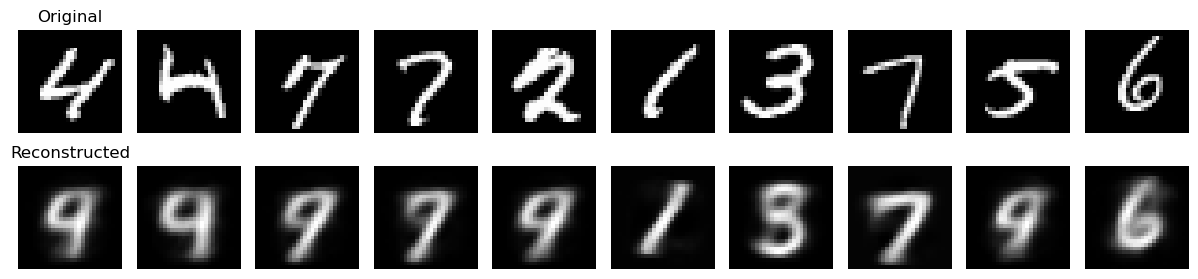

In [12]:
model.eval()

X_batch, _ = next(iter(reporting_loader))

with torch.no_grad():
    reconstructed = model(X_batch)

fig, axes = plt.subplots(2, 10, figsize=(12, 3))

for i in range(10):
    axes[0, i].imshow(X_batch[i].reshape(28, 28), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_title("Original")
axes[1, 0].set_title("Reconstructed")

plt.tight_layout()
plt.show()

The reconstruction was successful for some letters but not for others. The model was able to reconstruct digits such as 1, 3, 7, and 6, but several digits were incorrect, such as 9. Additionally, the reconstructed images were blurrier than the original images. This is likely because the bottleneck layer has two dimensions, causing the model to lose important information.

## 4. Visualize the Learned Representations (15 points)

Here you will explore the latent representations learned by your autoencoder.

1. Complete `extract_latent_features` to extract the latent (bottleneck) features and their corresponding labels, given a trained model.  
   Apply this function to the reporting set using the provided code. This should give you the transformed reporting set with the dimensions of the bottleneck (2).
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [13]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            encoded = model.encode(X_batch)
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

Once the missing parts above have been filled, uncomment the piece of code below and execute it to extract the latent features

In [14]:
latents_autoencoder, labels = extract_latent_features(model, reporting_loader)

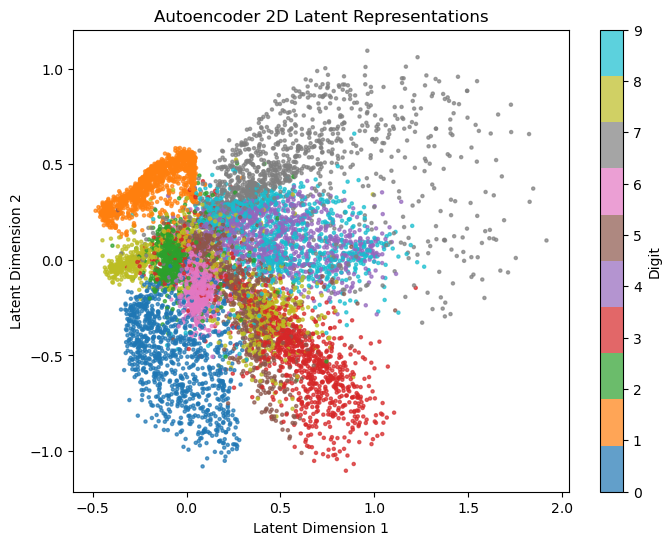

In [15]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    latents_autoencoder[:, 0],
    latents_autoencoder[:, 1],
    c=labels,
    cmap="tab10",
    s=5,
    alpha=0.7
)

plt.colorbar(scatter, label="Digit")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("Autoencoder 2D Latent Representations")
plt.show()

## 5. Compare with PCA (10 points)

Here you will compare the latent representations learned by your autoencoder with those obtained using a PCA.

1. Apply a PCA to the reporting set (without using the autoencoder) to reduce the data to the same dimensionality as your bottleneck (2 dimensions). Obviously, first use the rest of the data to learn these two components.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA) and briefly discuss the differences (if any) you observe.

Explained variance ratio: [0.09712354 0.07155898]
Total variance kept: 0.16868252


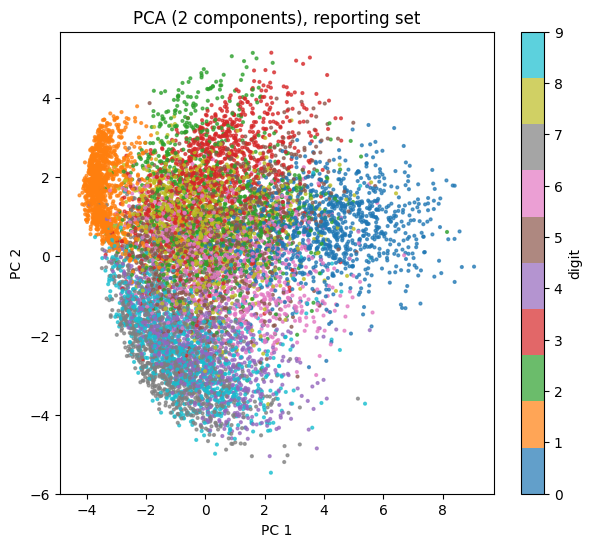

In [ ]:
from sklearn.decomposition import PCA

# learn the 2 components from the rest of the data (fitting + tuning), then apply to the reporting set
pca = PCA(n_components=2, random_state=42)
pca.fit(np.vstack([X_fit, X_tune]))
latents_pca = pca.transform(X_report)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance kept:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(7, 6))
sc = plt.scatter(latents_pca[:, 0], latents_pca[:, 1], c=y_report, cmap="tab10", s=4, alpha=0.7)
plt.colorbar(sc, label="digit")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("PCA (2 components), reporting set")
plt.show()

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

The main inefficiency we ran into was the one laptop rule in class. It really slowed us down because we could not use our normal workflow, where each of us works on our own part at the same time, and only one person could actually type or run code during the group time. It also messed with our documentation and with assigning work, since we did not have a clear place to write down who was doing which section, so some of it got decided late or only half remembered. Next lab, we will split up the sections and write down who owns what in our group chat and a shared notes doc before class starts, so the one laptop time is only used for discussing the answers. Then each of us will do our own part on our own laptop after class and commit to the shared repo with a clear message so everyone can see what changed.